# Container Ship Stowage Optimization with Agentic AI

**Author:** Nicole Riepl  
**Study Focus:** Cost saving and safety-focused cargo container loading

This Jupyter-style notebook supports the container-ship stowage study. It generates a reproducible synthetic dataset, performs EDA, creates a first-fit baseline, solves a mixed-integer linear programming (MILP) model, compares the results, and provides a LangGraph workflow for planning, validation, revision, and plain-English explanation.


## Study Question

Can a standard optimization model create a safer and more cost-efficient container loading plan than a simple first-fit loading method?

The analysis focuses on practical stowage features: container weight, length, destination order, refrigerated cargo, hazardous cargo, slot capacity, powered slots, approved hazardous slots, and simplified vessel balance. The LangGraph workflow does not replace the optimizer. It coordinates the process around the optimizer and explains the final plan in language a planner can understand.


In [33]:
import os
import json
import random
from pathlib import Path
from datetime import datetime

os.environ.setdefault("MPLCONFIGDIR", str((Path.cwd() / ".matplotlib_cache").resolve()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except Exception:
    def display(value):
        print(value)

from scipy.optimize import milp, LinearConstraint, Bounds
from scipy.sparse import lil_matrix, vstack

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)

DATA_DIR = Path("stowage_notebook_data")
DATA_DIR.mkdir(exist_ok=True)

print("Started:", datetime.now())
print("Output directory:", DATA_DIR.resolve())


Started: 2026-08-17 19:14:48.026145
Output directory: /Users/nicoleriepl/Downloads/stowage_notebook_data


## OpenAI Key Placeholder

Only the LangGraph explanation step requires an OpenAI key. Leave this blank until you are ready to run that section.


In [ ]:
# Paste your key here only while testing, then remove it before sharing the notebook.
# os.environ["OPENAI_API_KEY"] = key

OPENAI_MODEL = "gpt-4o-mini"
print("OpenAI key set:", bool(os.environ.get("OPENAI_API_KEY")))


OpenAI key set: True


## 1. Generate a Synthetic Dataset

Real carrier manifests and vessel bay plans would be preferable because they would reflect actual business operations. Since those files are often proprietary and were not available, this notebook creates a reproducible synthetic dataset that follows the structure needed for the study. The synthetic data includes a simplified vessel layout and a container manifest with realistic operational constraints.


In [36]:
def generate_vessel_slots(n_bays=10, rows_per_bay=6, tiers_per_row=4):
    records = []
    for bay in range(1, n_bays + 1):
        zone = "fore" if bay <= n_bays / 2 else "aft"
        for row in range(1, rows_per_bay + 1):
            side = "port" if row <= rows_per_bay / 2 else "starboard"
            for tier in range(1, tiers_per_row + 1):
                records.append({
                    "slot_id": f"B{bay:02d}-R{row:02d}-T{tier:02d}",
                    "bay": bay,
                    "row": row,
                    "tier": tier,
                    "zone": zone,
                    "side": side,
                    "length_capacity_ft": int(np.random.choice([20, 40], p=[0.35, 0.65])),
                    "max_weight_tons": float(32 if tier <= 2 else 26),
                    "has_power": bool(np.random.random() < (0.28 if tier <= 3 else 0.12)),
                    "hazmat_allowed": bool((tier <= 2) and (bay not in [1, n_bays]) and (row not in [1, rows_per_bay]))
                })
    return pd.DataFrame(records)

def generate_container_manifest(n_containers=204):
    records = []
    for i in range(1, n_containers + 1):
        length = int(np.random.choice([20, 40], p=[0.42, 0.58]))
        ctype = np.random.choice(["standard", "reefer", "hazmat"], p=[0.78, 0.14, 0.08])
        mean_weight = 17 if length == 20 else 22
        sd_weight = 6 if length == 20 else 7
        weight = float(np.clip(np.random.normal(mean_weight, sd_weight), 4, 32))
        records.append({
            "container_id": f"C{i:04d}",
            "length_ft": length,
            "weight_tons": round(weight, 2),
            "container_type": ctype,
            "requires_power": bool(ctype == "reefer"),
            "is_hazmat": bool(ctype == "hazmat"),
            "destination_order": int(np.random.choice([1, 2, 3, 4], p=[0.25, 0.30, 0.25, 0.20])),
            "priority": int(np.random.choice([1, 2, 3], p=[0.20, 0.55, 0.25]))
        })
    return pd.DataFrame(records)

slots = generate_vessel_slots()
manifest_raw = generate_container_manifest()

slots.to_csv(DATA_DIR / "vessel_slots.csv", index=False)
manifest_raw.to_csv(DATA_DIR / "container_manifest_raw.csv", index=False)

print(f"Generated {len(slots)} slots and {len(manifest_raw)} containers")
display(slots.head())
display(manifest_raw.head())


Generated 240 slots and 204 containers


,slot_id,bay,row,tier,zone,side,length_capacity_ft,max_weight_tons,has_power,hazmat_allowed
0,B01-R01-T01,1,1,1,fore,port,40,32.0,False,False
1,B01-R01-T02,1,1,2,fore,port,40,32.0,False,False
2,B01-R01-T03,1,1,3,fore,port,20,26.0,True,False
3,B01-R01-T04,1,1,4,fore,port,20,26.0,False,False
4,B01-R02-T01,1,2,1,fore,port,40,32.0,False,False


,container_id,length_ft,weight_tons,container_type,requires_power,is_hazmat,destination_order,priority
0,C0001,40,32.00,standard,False,False,3,3
1,C0002,20,12.40,standard,False,False,4,3
2,C0003,40,16.12,standard,False,False,2,2
3,C0004,40,17.80,standard,False,False,4,3
4,C0005,40,28.65,standard,False,False,3,1


## 2. Preprocess and Validate the Dataset

This section creates derived fields and builds a compatibility table. A compatible assignment means that the container can legally fit in the slot based on length, weight, reefer power, and hazardous-cargo permissions.


In [37]:
def preprocess_manifest(df):
    df = df.copy()
    df["container_id"] = df["container_id"].astype(str)
    df["length_ft"] = df["length_ft"].astype(int)
    df["weight_tons"] = df["weight_tons"].astype(float)
    df["requires_power"] = df["requires_power"].astype(bool)
    df["is_hazmat"] = df["is_hazmat"].astype(bool)
    df["heavy_container"] = df["weight_tons"] >= 24
    df["early_destination"] = df["destination_order"] <= 2
    df["special_requirement"] = df["requires_power"] | df["is_hazmat"]
    return df

def validate_inputs(manifest, slots):
    return {
        "manifest_missing_values": int(manifest.isna().sum().sum()),
        "slots_missing_values": int(slots.isna().sum().sum()),
        "duplicate_container_ids": int(manifest["container_id"].duplicated().sum()),
        "duplicate_slot_ids": int(slots["slot_id"].duplicated().sum()),
        "invalid_container_lengths": int((~manifest["length_ft"].isin([20, 40])).sum()),
        "invalid_slot_lengths": int((~slots["length_capacity_ft"].isin([20, 40])).sum()),
        "nonpositive_container_weights": int((manifest["weight_tons"] <= 0).sum()),
        "nonpositive_slot_limits": int((slots["max_weight_tons"] <= 0).sum())
    }

def build_compatibility_table(manifest, slots):
    rows = []
    for _, c in manifest.iterrows():
        feasible = slots[
            (slots["length_capacity_ft"] >= c["length_ft"]) &
            (slots["max_weight_tons"] >= c["weight_tons"]) &
            ((not bool(c["requires_power"])) | slots["has_power"]) &
            ((not bool(c["is_hazmat"])) | slots["hazmat_allowed"])
        ]
        for _, s in feasible.iterrows():
            rows.append({
                "container_id": c["container_id"],
                "slot_id": s["slot_id"],
                "weight_tons": c["weight_tons"],
                "destination_order": c["destination_order"],
                "bay": s["bay"],
                "row": s["row"],
                "tier": s["tier"],
                "side": s["side"],
                "zone": s["zone"],
                "weight_margin_tons": round(s["max_weight_tons"] - c["weight_tons"], 2)
            })
    return pd.DataFrame(rows)

manifest = preprocess_manifest(manifest_raw)
checks = validate_inputs(manifest, slots)
compatibility = build_compatibility_table(manifest, slots)

manifest.to_csv(DATA_DIR / "container_manifest_processed.csv", index=False)
compatibility.to_csv(DATA_DIR / "compatible_assignments.csv", index=False)

print(json.dumps(checks, indent=2))
print(f"Compatible assignments: {len(compatibility):,}")
print(f"Containers with at least one legal slot: {compatibility['container_id'].nunique()} of {len(manifest)}")


{
  "manifest_missing_values": 0,
  "slots_missing_values": 0,
  "duplicate_container_ids": 0,
  "duplicate_slot_ids": 0,
  "invalid_container_lengths": 0,
  "invalid_slot_lengths": 0,
  "nonpositive_container_weights": 0,
  "nonpositive_slot_limits": 0
}
Compatible assignments: 28,082
Containers with at least one legal slot: 204 of 204


## 3. Exploratory Data Analysis

The EDA describes the manifest and vessel layout before any model is applied. This helps identify the constraints that are most likely to influence loading difficulty.


In [38]:
summary = pd.DataFrame([{
    "containers": len(manifest),
    "slots": len(slots),
    "compatible_assignments": len(compatibility),
    "avg_weight_tons": round(manifest["weight_tons"].mean(), 2),
    "max_weight_tons": round(manifest["weight_tons"].max(), 2),
    "reefer_containers": int(manifest["requires_power"].sum()),
    "hazmat_containers": int(manifest["is_hazmat"].sum()),
    "powered_slots": int(slots["has_power"].sum()),
    "hazmat_allowed_slots": int(slots["hazmat_allowed"].sum())
}])
display(summary)
summary.to_csv(DATA_DIR / "eda_summary.csv", index=False)


,containers,slots,compatible_assignments,avg_weight_tons,max_weight_tons,reefer_containers,hazmat_containers,powered_slots,hazmat_allowed_slots
0,204,240,28082,20.06,32.0,33,15,59,64


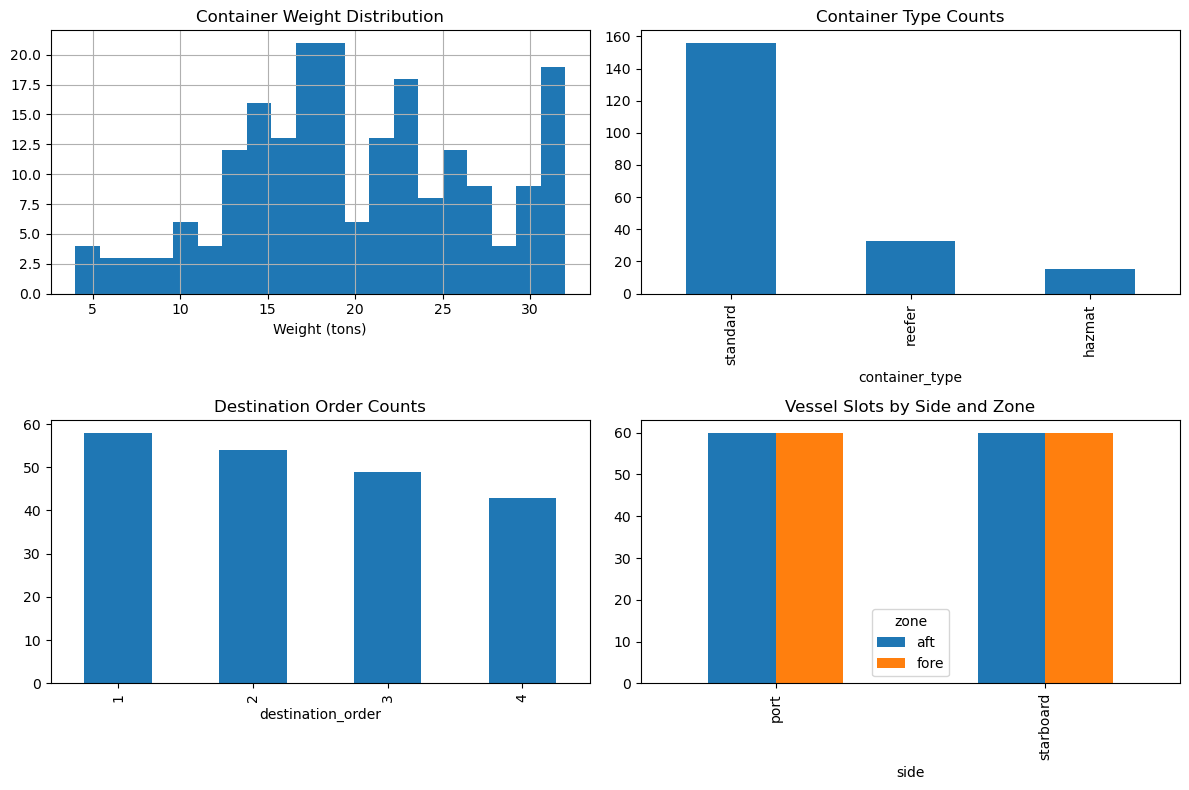

In [39]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
manifest["weight_tons"].hist(ax=axes[0,0], bins=20)
axes[0,0].set_title("Container Weight Distribution")
axes[0,0].set_xlabel("Weight (tons)")
manifest["container_type"].value_counts().plot(kind="bar", ax=axes[0,1])
axes[0,1].set_title("Container Type Counts")
manifest["destination_order"].value_counts().sort_index().plot(kind="bar", ax=axes[1,0])
axes[1,0].set_title("Destination Order Counts")
slots.groupby(["side", "zone"]).size().unstack().plot(kind="bar", ax=axes[1,1])
axes[1,1].set_title("Vessel Slots by Side and Zone")
plt.tight_layout()
plt.show()


,count,mean,std,min,25%,50%,75%,max
container_type,,,,,,,,
hazmat,15.0,51.73,11.88,41.0,41.0,41.0,64.0,64.0
reefer,33.0,46.18,13.91,20.0,39.0,39.0,59.0,59.0
standard,156.0,165.27,62.55,75.0,149.0,149.0,240.0,240.0


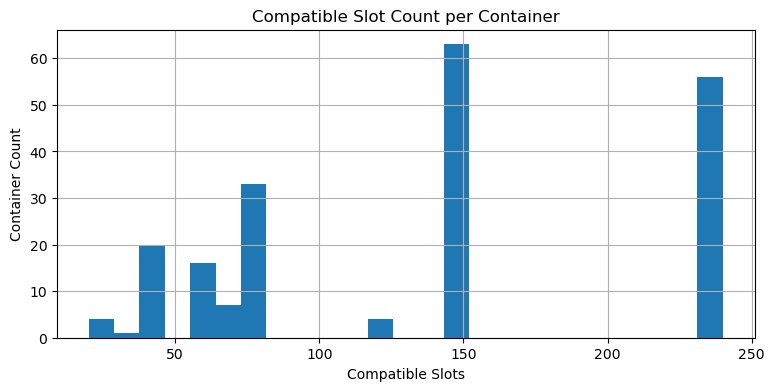

In [40]:
compat_counts = compatibility.groupby("container_id").size().rename("compatible_slot_count")
manifest_eda = manifest.merge(compat_counts, on="container_id", how="left")
manifest_eda["compatible_slot_count"] = manifest_eda["compatible_slot_count"].fillna(0).astype(int)

display(manifest_eda.groupby("container_type")["compatible_slot_count"].describe().round(2))
manifest_eda["compatible_slot_count"].hist(figsize=(9,4), bins=25)
plt.title("Compatible Slot Count per Container")
plt.xlabel("Compatible Slots")
plt.ylabel("Container Count")
plt.show()


## 4. Evaluation and Validation Functions

The same metrics are used for both the baseline and the optimizer so the comparison is fair.


In [41]:
def validate_plan(assignments, manifest, slots):
    issues = []
    if assignments.empty:
        return {"valid": False, "issues": ["No assignments were produced."]}
    if assignments["container_id"].duplicated().any(): issues.append("A container was assigned more than once.")
    if assignments["slot_id"].duplicated().any(): issues.append("A slot was used more than once.")
    plan = assignments.merge(manifest, on="container_id").merge(slots, on="slot_id")
    if (plan["length_ft"] > plan["length_capacity_ft"]).any(): issues.append("Length capacity violation.")
    if (plan["weight_tons"] > plan["max_weight_tons"]).any(): issues.append("Weight capacity violation.")
    if ((plan["requires_power"]) & (~plan["has_power"])).any(): issues.append("Reefer power violation.")
    if ((plan["is_hazmat"]) & (~plan["hazmat_allowed"])).any(): issues.append("Hazmat placement violation.")
    return {"valid": len(issues) == 0, "issues": issues}

def evaluate_plan(assignments, manifest, slots, plan_name):
    if assignments.empty:
        return {"plan_name": plan_name, "loaded_containers": 0, "loaded_percent": 0}
    plan = assignments.merge(manifest, on="container_id").merge(slots, on="slot_id")
    side_weights = plan.groupby("side")["weight_tons"].sum().to_dict()
    zone_weights = plan.groupby("zone")["weight_tons"].sum().to_dict()
    obstruction_count = 0
    for _, stack in plan.groupby(["bay", "row"]):
        stack = stack.sort_values("tier")
        for _, lower in stack.iterrows():
            above = stack[stack["tier"] > lower["tier"]]
            obstruction_count += int((above["destination_order"] > lower["destination_order"]).sum())
    return {
        "plan_name": plan_name,
        "loaded_containers": int(plan["container_id"].nunique()),
        "loaded_percent": round(100 * plan["container_id"].nunique() / len(manifest), 1),
        "total_weight_tons": round(float(plan["weight_tons"].sum()), 1),
        "port_starboard_imbalance_tons": round(abs(side_weights.get("port",0) - side_weights.get("starboard",0)), 1),
        "fore_aft_imbalance_tons": round(abs(zone_weights.get("fore",0) - zone_weights.get("aft",0)), 1),
        "heavy_height_cost": round(float((plan["weight_tons"] * plan["tier"]).sum()), 1),
        "destination_obstruction_count": int(obstruction_count),
        "reefer_violations": int(((plan["requires_power"]) & (~plan["has_power"])).sum()),
        "hazmat_violations": int(((plan["is_hazmat"]) & (~plan["hazmat_allowed"])).sum())
    }


## 5. First-Fit Baseline

This baseline loads special containers first, then higher-priority and heavier containers. It assigns each container to the first legal open slot.


In [42]:
def first_fit_baseline(manifest, slots):
    assigned = []
    used_slots = set()
    ordered_containers = manifest.sort_values(["special_requirement", "priority", "weight_tons", "destination_order"], ascending=[False, True, False, True])
    ordered_slots = slots.sort_values(["tier", "bay", "row"])
    for _, c in ordered_containers.iterrows():
        feasible = ordered_slots[
            (~ordered_slots["slot_id"].isin(used_slots)) &
            (ordered_slots["length_capacity_ft"] >= c["length_ft"]) &
            (ordered_slots["max_weight_tons"] >= c["weight_tons"]) &
            ((not bool(c["requires_power"])) | ordered_slots["has_power"]) &
            ((not bool(c["is_hazmat"])) | ordered_slots["hazmat_allowed"])
        ]
        if len(feasible):
            slot_id = feasible.iloc[0]["slot_id"]
            assigned.append({"container_id": c["container_id"], "slot_id": slot_id})
            used_slots.add(slot_id)
    return pd.DataFrame(assigned)

baseline_assignments = first_fit_baseline(manifest, slots)
baseline_metrics = evaluate_plan(baseline_assignments, manifest, slots, "First-Fit Baseline")
baseline_assignments.to_csv(DATA_DIR / "baseline_assignments.csv", index=False)
print(baseline_metrics)
print(validate_plan(baseline_assignments, manifest, slots))


{'plan_name': 'First-Fit Baseline', 'loaded_containers': 197, 'loaded_percent': 96.6, 'total_weight_tons': 3877.4, 'port_starboard_imbalance_tons': 118.3, 'fore_aft_imbalance_tons': 593.5, 'heavy_height_cost': 8014.7, 'destination_obstruction_count': 102, 'reefer_violations': 0, 'hazmat_violations': 0}
{'valid': True, 'issues': []}


## 6. MILP Optimizer

The MILP makes a binary decision for each legal container-slot pair. It rewards loaded containers and penalizes higher placement of heavy containers, later-destination containers placed high in stacks, and vessel imbalance.


In [43]:
def run_milp_optimizer(manifest, slots, compatibility, load_reward=1000, tier_penalty=3, obstruction_proxy_penalty=10, balance_limit_tons=120, time_limit=120):
    pairs = compatibility.reset_index(drop=True).copy()
    n = len(pairs)
    c = np.zeros(n)
    container_lookup = manifest.set_index("container_id")
    slot_lookup = slots.set_index("slot_id")
    for i, p in pairs.iterrows():
        cont = container_lookup.loc[p["container_id"]]
        slot = slot_lookup.loc[p["slot_id"]]
        early_reward = (5 - cont["destination_order"]) * 5
        heavy_low_penalty = tier_penalty * cont["weight_tons"] * slot["tier"]
        destination_height_penalty = obstruction_proxy_penalty * cont["destination_order"] * slot["tier"]
        c[i] = -load_reward - early_reward + heavy_low_penalty + destination_height_penalty
    constraints, lb, ub = [], [], []
    for _, idxs in pairs.groupby("container_id").groups.items():
        row = lil_matrix((1, n)); row[0, list(idxs)] = 1
        constraints.append(row.tocsr()); lb.append(0); ub.append(1)
    for _, idxs in pairs.groupby("slot_id").groups.items():
        row = lil_matrix((1, n)); row[0, list(idxs)] = 1
        constraints.append(row.tocsr()); lb.append(0); ub.append(1)
    side_row = lil_matrix((1, n))
    zone_row = lil_matrix((1, n))
    for i, p in pairs.iterrows():
        w = container_lookup.loc[p["container_id"], "weight_tons"]
        side_row[0, i] = w if slot_lookup.loc[p["slot_id"], "side"] == "port" else -w
        zone_row[0, i] = w if slot_lookup.loc[p["slot_id"], "zone"] == "fore" else -w
    constraints += [side_row.tocsr(), zone_row.tocsr()]
    lb += [-balance_limit_tons, -balance_limit_tons]
    ub += [balance_limit_tons, balance_limit_tons]
    A = vstack(constraints).tocsr()
    result = milp(c=c, integrality=np.ones(n), bounds=Bounds(0, 1), constraints=LinearConstraint(A, np.array(lb), np.array(ub)), options={"time_limit": time_limit})
    selected = pd.DataFrame(columns=["container_id", "slot_id"])
    if result.x is not None:
        selected = pairs.iloc[np.where(result.x > 0.5)[0]][["container_id", "slot_id"]].copy()
    return result, selected

milp_result, milp_assignments = run_milp_optimizer(manifest, slots, compatibility)
milp_metrics = evaluate_plan(milp_assignments, manifest, slots, "MILP Optimizer")
milp_assignments.to_csv(DATA_DIR / "milp_assignments.csv", index=False)
print("Solver success:", milp_result.success)
print("Solver message:", milp_result.message)
print(milp_metrics)
print(validate_plan(milp_assignments, manifest, slots))


Solver success: True
Solver message: Optimization terminated successfully. (HiGHS Status 7: Optimal)
{'plan_name': 'MILP Optimizer', 'loaded_containers': 204, 'loaded_percent': 100.0, 'total_weight_tons': 4092.2, 'port_starboard_imbalance_tons': 52.9, 'fore_aft_imbalance_tons': 113.6, 'heavy_height_cost': 8127.8, 'destination_obstruction_count': 52, 'reefer_violations': 0, 'hazmat_violations': 0}
{'valid': True, 'issues': []}


## 7. Compare Model Results

Lower imbalance, lower heavy-height cost, and fewer destination obstructions are preferred. Higher loaded percentage is preferred.


,plan_name,loaded_containers,loaded_percent,total_weight_tons,port_starboard_imbalance_tons,fore_aft_imbalance_tons,heavy_height_cost,destination_obstruction_count,reefer_violations,hazmat_violations
0,First-Fit Baseline,197,96.6,3877.4,118.3,593.5,8014.7,102,0,0
1,MILP Optimizer,204,100.0,4092.2,52.9,113.6,8127.8,52,0,0


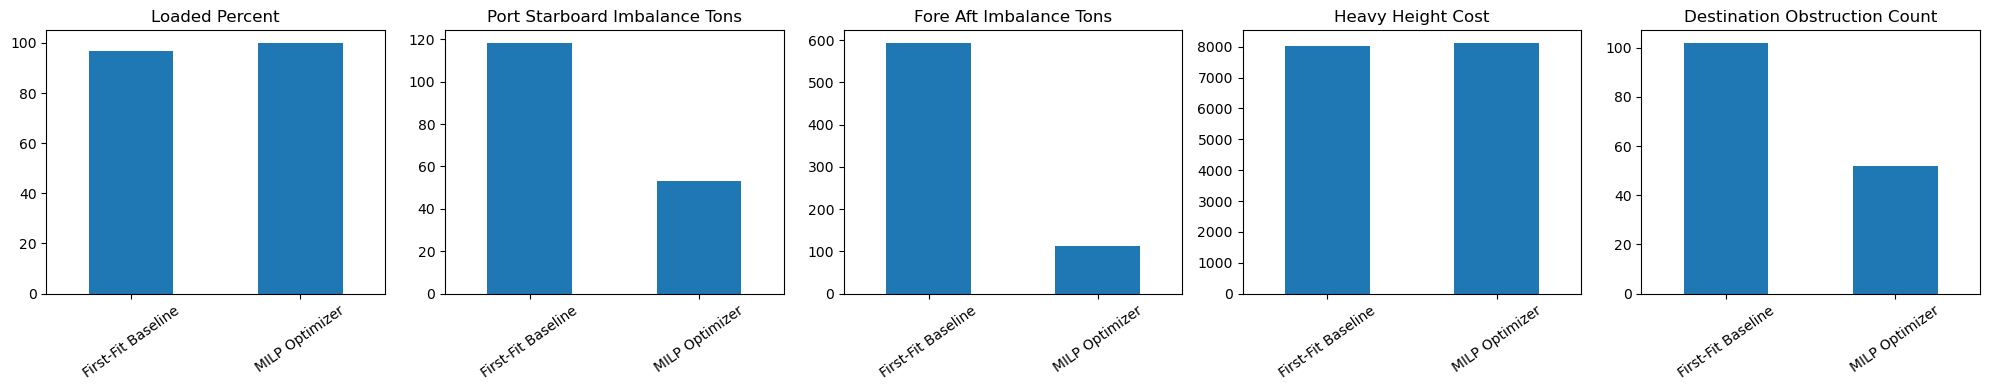

In [44]:
metrics_df = pd.DataFrame([baseline_metrics, milp_metrics])
metrics_df.to_csv(DATA_DIR / "model_comparison_metrics.csv", index=False)
display(metrics_df)

chart_metrics = ["loaded_percent", "port_starboard_imbalance_tons", "fore_aft_imbalance_tons", "heavy_height_cost", "destination_obstruction_count"]
fig, axes = plt.subplots(1, len(chart_metrics), figsize=(20, 4))
for ax, metric in zip(axes, chart_metrics):
    metrics_df.plot(kind="bar", x="plan_name", y=metric, ax=ax, legend=False)
    ax.set_title(metric.replace("_", " ").title())
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()


## 8. Demand Sensitivity Analysis

The same experiment is repeated at different vessel-demand levels. This tests whether optimization becomes more valuable as the ship becomes more constrained.


In [45]:
def run_scenario(demand_fraction):
    n = int(len(manifest) * demand_fraction)
    subset = manifest.sample(n=n, random_state=int(demand_fraction * 1000)).copy()
    compat = build_compatibility_table(subset, slots)
    base = first_fit_baseline(subset, slots)
    base_m = evaluate_plan(base, subset, slots, f"First-Fit {int(demand_fraction*100)}%")
    result, opt = run_milp_optimizer(subset, slots, compat, time_limit=60)
    opt_m = evaluate_plan(opt, subset, slots, f"MILP {int(demand_fraction*100)}%")
    opt_m["solver_success"] = bool(result.success)
    base_m["solver_success"] = None
    return base_m, opt_m

scenario_rows = []
for frac in [0.70, 0.85, 0.95, 1.00]:
    scenario_rows.extend(run_scenario(frac))
scenario_df = pd.DataFrame(scenario_rows)
scenario_df.to_csv(DATA_DIR / "demand_sensitivity_metrics.csv", index=False)
display(scenario_df)


,plan_name,loaded_containers,loaded_percent,total_weight_tons,port_starboard_imbalance_tons,fore_aft_imbalance_tons,heavy_height_cost,destination_obstruction_count,reefer_violations,hazmat_violations,solver_success
0,First-Fit 70%,142,100.0,2802.1,111.5,435.4,4653.5,43,0,0,None
1,MILP 70%,142,100.0,2802.2,18.3,68.1,4352.7,15,0,0,True
2,First-Fit 85%,167,96.5,3278.5,56.8,307.4,5967.8,66,0,0,None
3,MILP 85%,173,100.0,3461.7,17.5,111.4,6113.3,34,0,0,True
4,First-Fit 95%,186,96.4,3655.0,1.6,374.9,7245.2,85,0,0,None
5,MILP 95%,193,100.0,3869.8,8.3,7.7,7385.3,40,0,0,True
6,First-Fit 100%,197,96.6,3877.4,118.3,593.5,8014.7,102,0,0,None
7,MILP 100%,204,100.0,4092.2,70.2,112.5,8127.8,52,0,0,True


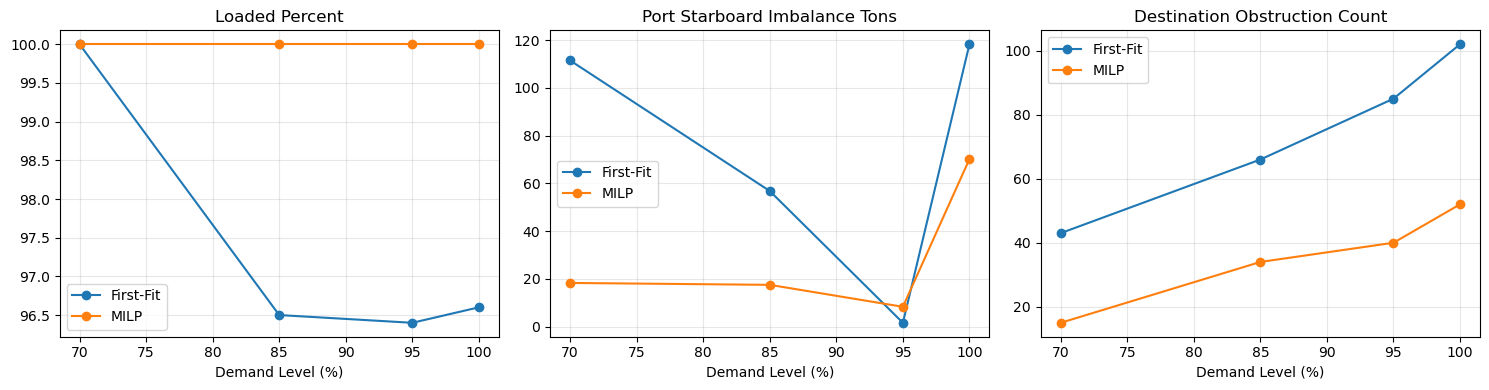

In [46]:
scenario_plot = scenario_df.copy()
scenario_plot["method"] = scenario_plot["plan_name"].str.extract(r"^(First-Fit|MILP)")
scenario_plot["demand_level"] = scenario_plot["plan_name"].str.extract(r"(\d+)%").astype(int)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, ["loaded_percent", "port_starboard_imbalance_tons", "destination_obstruction_count"]):
    for method, group in scenario_plot.groupby("method"):
        ax.plot(group["demand_level"], group[metric], marker="o", label=method)
    ax.set_title(metric.replace("_", " ").title())
    ax.set_xlabel("Demand Level (%)")
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()


## 9. Plain-English Findings Generator

This helper turns model metrics into draft findings. The LangGraph explanation agent can later do this with more natural language, but this deterministic version is useful for checking the numbers.


In [47]:
def plain_english_findings(metrics_df):
    base = metrics_df.iloc[0]
    opt = metrics_df.iloc[1]
    return f"""
The first-fit baseline loaded {base['loaded_percent']}% of containers, while the MILP optimizer loaded {opt['loaded_percent']}%.
The MILP changed port-starboard imbalance from {base['port_starboard_imbalance_tons']} tons to {opt['port_starboard_imbalance_tons']} tons.
The MILP changed fore-aft imbalance from {base['fore_aft_imbalance_tons']} tons to {opt['fore_aft_imbalance_tons']} tons.
The destination obstruction count changed from {base['destination_obstruction_count']} to {opt['destination_obstruction_count']}.
Overall, the optimized plan is designed to improve vessel balance, reduce avoidable rehandling, and maintain hard safety constraints.
""".strip()

print(plain_english_findings(metrics_df))


The first-fit baseline loaded 96.6% of containers, while the MILP optimizer loaded 100.0%.
The MILP changed port-starboard imbalance from 118.3 tons to 52.9 tons.
The MILP changed fore-aft imbalance from 593.5 tons to 113.6 tons.
The destination obstruction count changed from 102 to 52.
Overall, the optimized plan is designed to improve vessel balance, reduce avoidable rehandling, and maintain hard safety constraints.


## 10. LangGraph Workflow

Install LangGraph in your notebook environment before running this section:

```python
%pip install langgraph langchain-openai
```

The workflow has five nodes: planning, optimization, validation, revision, and explanation. The optimizer and validator remain deterministic. The LLM is used only to translate the final plan into understandable language and to help structure soft planning preferences.


In [48]:
try:
    from typing import TypedDict, Dict, Any
    from langgraph.graph import StateGraph, END
    from langchain_openai import ChatOpenAI
    LANGGRAPH_AVAILABLE = True
except Exception as exc:
    LANGGRAPH_AVAILABLE = False
    print("LangGraph dependencies are not installed yet.")
    print("Install with: %pip install langgraph langchain-openai")
    print("Import error:", exc)


In [49]:
if LANGGRAPH_AVAILABLE:
    class StowageState(TypedDict):
        user_request: str
        optimizer_settings: Dict[str, Any]
        assignments: Any
        metrics: Dict[str, Any]
        validation: Dict[str, Any]
        explanation: str
        retry_count: int

    llm = ChatOpenAI(model=OPENAI_MODEL, temperature=0)

    def planning_agent(state: StowageState):
        # Conservative defaults. Safety constraints are not changed by the LLM.
        return {"optimizer_settings": {
            "load_reward": 1000,
            "tier_penalty": 3,
            "obstruction_proxy_penalty": 10,
            "balance_limit_tons": 120,
            "maximum_retries": 3
        }, "retry_count": state.get("retry_count", 0)}

    def milp_tool_node(state: StowageState):
        s = state["optimizer_settings"]
        result, assignments = run_milp_optimizer(manifest, slots, compatibility, s["load_reward"], s["tier_penalty"], s["obstruction_proxy_penalty"], s["balance_limit_tons"])
        metrics = evaluate_plan(assignments, manifest, slots, "LangGraph MILP Plan")
        metrics["solver_success"] = bool(result.success)
        metrics["solver_message"] = str(result.message)
        return {"assignments": assignments, "metrics": metrics}

    def validation_node(state: StowageState):
        return {"validation": validate_plan(state["assignments"], manifest, slots)}

    def revision_agent(state: StowageState):
        settings = dict(state["optimizer_settings"])
        settings["tier_penalty"] += 1
        settings["obstruction_proxy_penalty"] += 2
        return {"optimizer_settings": settings, "retry_count": state.get("retry_count", 0) + 1}

    def explanation_agent(state: StowageState):
        prompt = f"""
        Explain this container stowage plan in plain English for a port operations audience.
        Do not invent details. Discuss cost savings, vessel stability, special cargo compliance, and tradeoffs.
        Metrics: {state['metrics']}
        Validation: {state['validation']}
        """
        response = llm.invoke(prompt)
        return {"explanation": response.content}

    def route_after_validation(state: StowageState):
        if state["validation"].get("valid"):
            return "explain"
        if state.get("retry_count", 0) >= state["optimizer_settings"].get("maximum_retries", 3):
            return "explain"
        return "revise"

    workflow = StateGraph(StowageState)
    workflow.add_node("plan", planning_agent)
    workflow.add_node("optimize", milp_tool_node)
    workflow.add_node("validate", validation_node)
    workflow.add_node("revise", revision_agent)
    workflow.add_node("explain", explanation_agent)
    workflow.set_entry_point("plan")
    workflow.add_edge("plan", "optimize")
    workflow.add_edge("optimize", "validate")
    workflow.add_conditional_edges("validate", route_after_validation, {"explain": "explain", "revise": "revise"})
    workflow.add_edge("revise", "optimize")
    workflow.add_edge("explain", END)
    stowage_app = workflow.compile()
    print("LangGraph workflow compiled.")
else:
    print("Skipping workflow compile until dependencies are installed.")


LangGraph workflow compiled.


In [50]:
if LANGGRAPH_AVAILABLE:
    final_state = stowage_app.invoke({
        "user_request": "Create a safe and cost-efficient loading plan that prioritizes balance and early destination containers.",
        "optimizer_settings": {},
        "assignments": None,
        "metrics": {},
        "validation": {},
        "explanation": "",
        "retry_count": 0
    })
    print(final_state["explanation"])


The "LangGraph MILP Plan" is a comprehensive container stowage plan designed for efficient port operations. Here’s a breakdown of its key aspects:

1. **Loaded Containers and Capacity**: The plan has successfully loaded 204 containers, achieving a full loading percentage of 100%. This means that the vessel is at maximum capacity, which is essential for optimizing shipping costs and ensuring that the vessel is fully utilized.

2. **Total Weight**: The total weight of the loaded containers is 4,092.2 tons. This weight is crucial for calculating the vessel's stability and ensuring that it adheres to safety regulations.

3. **Vessel Stability**: The plan shows a port-starboard imbalance of 52.9 tons and a fore-aft imbalance of 113.6 tons. While these imbalances are present, they are within acceptable limits for safe vessel operation. However, it’s important to monitor these metrics closely, as significant imbalances can affect the vessel's stability during transit.

4. **Cost Savings**: Th

## 11. Exported Files

The notebook exports all generated and modeled data to `stowage_notebook_data/`. These files can support the Data, Methods, Results, and Analysis sections of the report.


In [51]:
print("Exported files:")
for file in sorted(DATA_DIR.glob("*.csv")):
    print("-", file)


Exported files:
- stowage_notebook_data/baseline_assignments.csv
- stowage_notebook_data/compatible_assignments.csv
- stowage_notebook_data/container_manifest_processed.csv
- stowage_notebook_data/container_manifest_raw.csv
- stowage_notebook_data/demand_sensitivity_metrics.csv
- stowage_notebook_data/eda_summary.csv
- stowage_notebook_data/milp_assignments.csv
- stowage_notebook_data/model_comparison_metrics.csv
- stowage_notebook_data/vessel_slots.csv
